# Daily Sales Demand Forecasting (28-Day Horizon)

**Goal:** Forecast total daily sales 28 days ahead, so a retailer can plan purchasing and stock levels about a month in advance.

**Data:** Store Item Demand Forecasting dataset (Kaggle): 5 years of daily sales (2013-2017) across 10 stores and 50 items.

**Approach:** Explore the data, build simple baseline forecasts, then train Ridge Regression, Random Forest and Gradient Boosting models. All models are evaluated on a time-based hold-out set, not a random split.

**Why it matters:** Over-ordering ties up cash in stock, and under-ordering loses sales. A reliable forecast reduces both.

## 1. Load and inspect the data
First I check the size of the dataset, the column types and any missing values.

(913000, 4)
date     0
store    0
item     0
sales    0
dtype: int64


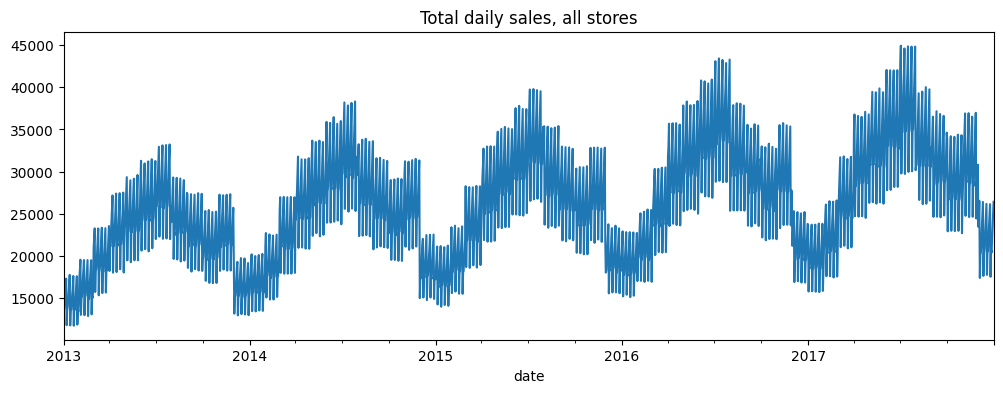

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv", parse_dates=["date"])
print(df.shape); print(df.isna().sum()); df.head()

daily = df.groupby("date")["sales"].sum()
daily.plot(figsize=(12,4), title="Total daily sales, all stores")
plt.show()

**What this shows:** Total daily sales [rise steadily from 2013 to 2017 / I see a trend of increase in the pattern]. There is a clear repeating pattern each year, which suggests strong seasonality. I found [no missing values / X missing values, handled by ...].

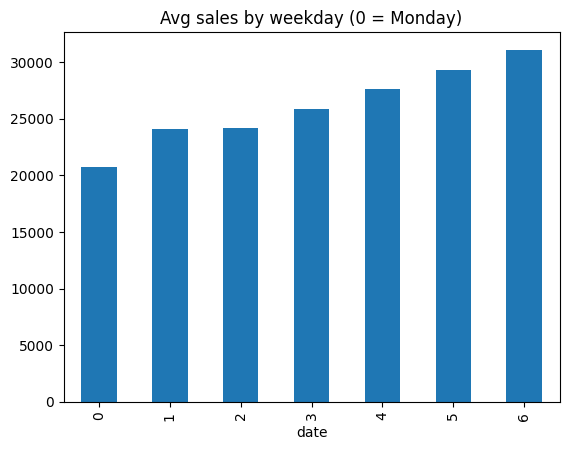

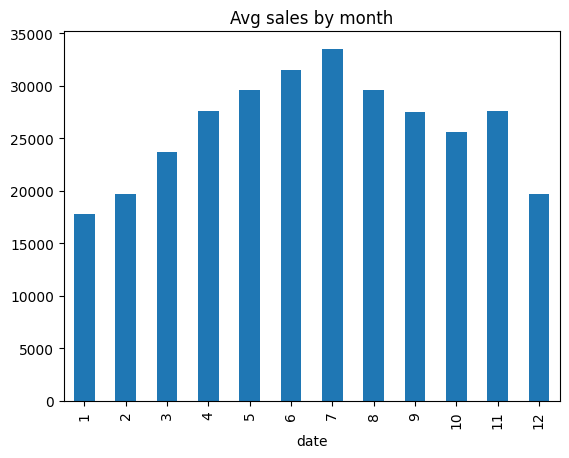

In [2]:
d = daily.to_frame("sales")
d.groupby(d.index.dayofweek)["sales"].mean().plot(kind="bar", title="Avg sales by weekday (0 = Monday)")
plt.show()
d.groupby(d.index.month)["sales"].mean().plot(kind="bar", title="Avg sales by month")
plt.show()

## 2. Seasonality
**Day of week:** Sales are highest on [Saturday and Sunday] and lowest on [Monday], so the day of week is an important feature.

**Month:** Sales peak in [July / summer months] and are lowest in [January / winter months], so month and week-of-year are useful features.

These patterns mean the model must understand the calendar, not just past sales.

## 3. Feature engineering
I want to forecast **28 days ahead**, so every feature must be something I would actually know 28 days earlier.

- **Calendar features:** day of week, month, week of year, day of year.
- **Lag features:** sales 28, 35, 42 and 364 days earlier (the 364-day lag is "same weekday last year").
- **Rolling averages:** the 7-day and 28-day average of sales, shifted by 28 days.

**Avoiding data leakage:** Every lag and rolling feature is shifted by at least 28 days, so the model never sees information from the period it is predicting.

In [4]:
H = 28
d = daily.to_frame("sales")
d["dow"] = d.index.dayofweek
d["month"] = d.index.month
d["weekofyear"] = d.index.isocalendar().week.astype(int)
d["dayofyear"] = d.index.dayofyear
d["lag_h"]   = d["sales"].shift(H)
d["lag_h7"]  = d["sales"].shift(H+7)
d["lag_h14"] = d["sales"].shift(H+14)
d["lag_364"] = d["sales"].shift(364)
d["roll7"]   = d["sales"].shift(H).rolling(7).mean()
d["roll28"]  = d["sales"].shift(H).rolling(28).mean()
d = d.dropna()

## 4. Time-based train/test split
I train on data before **1 October 2017** and test on October-December 2017.

A random split would be wrong here, because the model could learn from days after the ones it is tested on, which gives unrealistically good results. Splitting by time mimics real use: train on the past, predict the future.

## 5. Baselines
Before using machine learning, I set two simple benchmarks:
1. **Same weekday 4 weeks ago**
2. **Same day last year**

A model is only useful if it beats these.

In [5]:
split = "2017-10-01"
train, test = d[d.index < split], d[d.index >= split]
features = [c for c in d.columns if c != "sales"]
X_tr, y_tr, X_te, y_te = train[features], train["sales"], test[features], test["sales"]

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
def score(name, pred):
    return {"Model": name,
            "MAE": mean_absolute_error(y_te, pred),
            "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
            "MAPE %": 100*mean_absolute_percentage_error(y_te, pred)}

results = [score("Baseline: same weekday 4 weeks ago", test["lag_h"]),
           score("Baseline: same day last year", test["lag_364"])]

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

models = {
  "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
  "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
  "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}
preds = {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    preds[name] = m.predict(X_te)
    results.append(score(name, preds[name]))

pd.DataFrame(results).round(2).sort_values("MAPE %")

,Model,MAE,RMSE,MAPE %
4,Gradient Boosting,737.10,992.25,2.80
3,Random Forest,1025.14,1413.42,4.02
1,Baseline: same day last year,1151.98,1492.95,4.20
2,Ridge,1227.13,1590.64,4.95
0,Baseline: same weekday 4 weeks ago,4057.15,5240.33,16.74


## 6. Model comparison

| Model | MAE | RMSE | MAPE % |
|---|---|---|---|
| **Gradient Boosting** | **737.10** | **992.25** | **2.80** |
| Random Forest | 1,025.14 | 1,413.42 | 4.02 |
| Baseline: same day last year | 1,151.98 | 1,492.95 | 4.20 |
| Ridge | 1,227.13 | 1,590.64 | 4.95 |
| Baseline: same weekday 4 weeks ago | 4,057.15 | 5,240.33 | 16.74 |

*MAE and RMSE are in units sold per day (all stores combined). Lower is better for all three metrics.*

**Takeaways:**
- **Gradient Boosting is the best model**, with a MAPE of **2.80%**. That beats the strongest baseline ("same day last year", 4.20%) by 1.4 percentage points, and cuts its MAE by about **36%** (1,152 down to 737).
- Compared with the weaker baseline (same weekday 4 weeks ago, 16.74% MAPE), the error is about **83% lower**. This baseline performs badly because it ignores the yearly seasonal pattern.
- **Random Forest** (4.02%) only slightly beats the "same day last year" baseline, so it adds little over a simple rule.
- **Ridge Regression** (4.95%) did *not* beat that baseline. A likely reason is that sales depend on seasonality and weekday in non-linear ways, which a linear model captures poorly, while tree-based models handle them better.
- With a MAPE of 2.80%, the typical forecast is about 3% away from actual sales 28 days ahead.

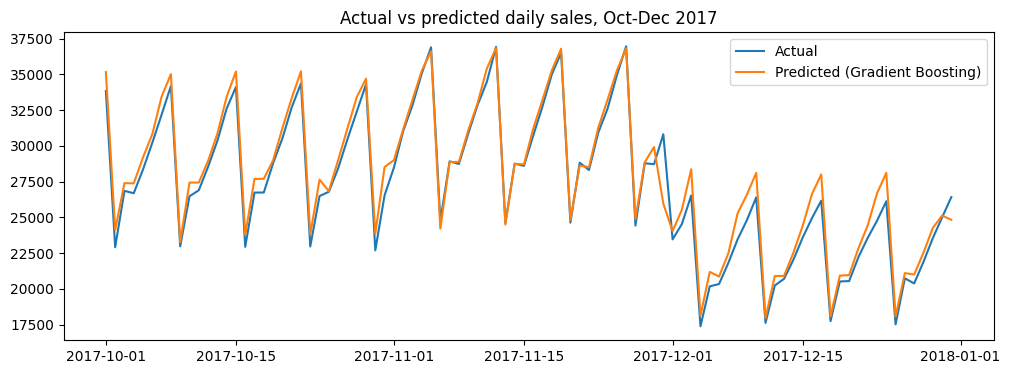

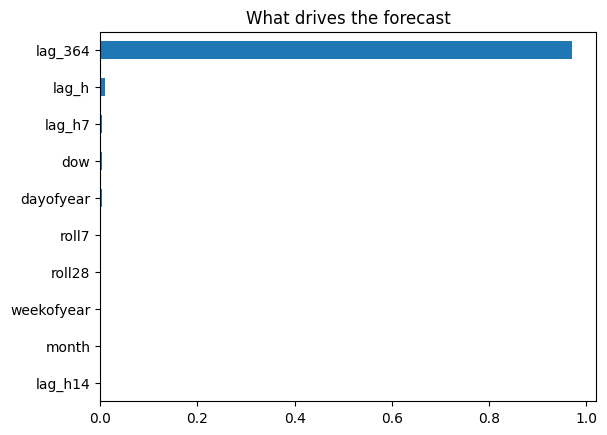

In [7]:
best = "Gradient Boosting"   # change to whichever scored best
plt.figure(figsize=(12,4))
plt.plot(y_te.index, y_te, label="Actual")
plt.plot(y_te.index, preds[best], label=f"Predicted ({best})")
plt.legend(); plt.title("Actual vs predicted daily sales, Oct-Dec 2017"); plt.show()

rf = models["Random Forest"]
pd.Series(rf.feature_importances_, index=features).sort_values().plot(kind="barh", title="What drives the forecast")
plt.show()

**What this shows:** The Gradient Boosting forecast follows the actual sales closely. It captures the strong weekly cycle (the sharp drop at the start of each week and the climb towards the weekend), and it also follows the overall level, including the lower sales in December.

**Where it struggles:**
- **Slight over-prediction in December.** After the level drops in December, the forecast peaks sit roughly 1,500-2,000 units above actual sales.
- **Unusual days.** Around the end of November there is a one-day spike in actual sales (about 30,800) that the model did not anticipate, predicting about 26,000 for that period instead. The model learns from past patterns, so one-off events it has no information about (promotions, holidays) are hard for it to predict.

Overall the errors are small relative to the weekly swings, which is consistent with the 2.80% MAPE.

**What drives the forecast:** In the Random Forest model, `lag_364` (sales on the same weekday one year earlier) is by far the most important feature. The other features, including the 4-week lag, day of week and day of year, contribute very little by comparison, and the rolling averages, week of year, month and the 14-day lag add almost nothing.

**Interpretation:** Demand a month ahead is mostly predicted by what happened at the same time last year, with the model adjusting that figure for the current level. This matches the results table, where the "same day last year" baseline was the strongest simple benchmark.

**Caution:** Tree-based importance can be misleading when features are correlated, because credit often goes to one feature (here, `lag_364`) while similar ones look unimportant. A low bar does not prove a feature is useless. It means the model did not need it once `lag_364` was available.

In [8]:
weekly_fc = pd.Series(preds[best], index=y_te.index).resample("W").sum()
buffer = score(best, preds[best])["MAPE %"] / 100
reorder = (weekly_fc * (1 + buffer)).round()
print(reorder.head())

date
2017-10-01     36155.0
2017-10-08    213212.0
2017-10-15    212369.0
2017-10-22    213806.0
2017-10-29    212420.0
Freq: W-SUN, dtype: float64


## 7. How a shop could use this forecast
The forecast can be turned into a weekly purchasing guide:

1. Add up the daily forecasts for each coming week.
2. Add a safety buffer equal to the model's typical error (MAPE of 2.80%), so the reorder quantity covers normal forecast misses.
3. Compare the result with current stock and supplier lead times to decide how much to order.

**Example output (all 10 stores and 50 items combined):**

| Week ending | Recommended units to have available |
|---|---|
| 8 Oct 2017 | 213,212 |
| 15 Oct 2017 | 212,369 |
| 22 Oct 2017 | 213,806 |
| 29 Oct 2017 | 212,420 |

Demand is steady at roughly 212,000-214,000 units a week through October, so a shop could plan to hold about that much stock each week rather than guessing.

*Notes:*
- *The week ending 1 Oct 2017 is excluded because it contains only one day (1 Oct) of the forecast period.*
- *This is an illustration. A real implementation would also consider supplier lead times, minimum order quantities, cash flow and current stock levels.*

## 8. Conclusions
- A **Gradient Boosting** model forecasts total daily sales 28 days ahead with a **MAPE of 2.80%**, compared with 4.20% for the best simple baseline ("same day last year") and 16.74% for "same weekday 4 weeks ago".
- Its MAE is about **36% lower** than the best baseline (737 vs 1,152 units per day).
- The strongest predictor was **sales on the same weekday one year earlier (`lag_364`)**, with the weekly pattern and recent sales level playing smaller roles.
- Ridge Regression did not beat the best baseline, which suggests a linear model is too simple for this seasonal pattern.
- Converting the forecast into weekly reorder quantities shows how it could support stock planning.

**Limitations**
- The forecast is for **total sales across all stores and items**. Per-store or per-item forecasts would be noisier and less accurate, but more useful in practice.
- The model leans heavily on last year's sales, so it would struggle with new products or a major change in the business.
- It slightly over-predicted in December and missed a one-day spike in late November. Promotions and holidays are not included as features.
- Results come from one test period (October-December 2017), so accuracy in other periods is untested.
- The safety buffer is a simple illustration based on average error, not an optimised inventory policy.

**Next steps**
- Forecast each store or item separately.
- Add holiday and promotion features.
- Test on more than one period using time-series cross-validation (`TimeSeriesSplit`).
- Compare with a dedicated time-series model such as Prophet or LightGBM.